<a href="https://colab.research.google.com/github/hiba-ai-ing/projet-mL/blob/main/SABIR_HIBA_TP6_ML_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Travaux Pratiques N°6 : Classification binaire par
régression logistique — Implémentation et évaluation des
performances**




---




**Partie I : Questions de réflexion**



**Q1) Expliquez ce que signifient les quatre éléments d’une matrice de confusion: True Positive (TP),
True Negative (TN), False Positive (FP) et False Negative (FN).**


Signification des quatre éléments

1. True Positive (TP) – Vrai Positif
Le modèle prédit positif et l’exemple est réellement positif. C’est une bonne prédiction.
Exemple : un patient malade est correctement diagnostiqué comme malade.

2. True Negative (TN) – Vrai Négatif
Le modèle prédit négatif et l’exemple est réellement négatif. C’est une bonne prédiction.
Exemple : un patient sain est correctement diagnostiqué comme sain.

3. False Positive (FP) – Faux Positif (erreur de type I)
Le modèle prédit positif alors que l’exemple est réellement négatif. C’est une fausse alarme.
Exemple : un patient sain est diagnostiqué à tort comme malade.

4. False Negative (FN) – Faux Négatif (erreur de type II)
Le modèle prédit négatif alors que l’exemple est réellement positif. C’est un cas manqué.
Exemple : un patient malade est diagnostiqué à tort comme sain.
---

**Q2) Expliquez la signification des métriques suivantes et donnez leurs formules de calcul :
Accuracy, Précision, Rappel, Spécificité, score F1.**

**1. Accuracy (exactitude)**

Signification : part totale de prédictions correctes. Elle répond à la question : le modèle a-t-il globalement bien décidé ?


Remarque : elle devient trompeuse quand la classe positive est rare.
Exemple : sur 1 000 e-mails dont 10 spams, un modèle qui prédit toujours « non-spam » obtient TN = 990, TP = 0, FP = 0, FN = 10, soit 99 % d’accuracy, alors qu’il ne détecte aucun spam.

**2. Précision**

Signification : parmi les exemples prédits positifs, part de ceux qui sont réellement positifs. Elle mesure la fiabilité des alertes positives.


Utile quand un FP coûte cher (ex. un bon e-mail envoyé à tort en spam).
Exemple : le filtre marque 50 messages « spam », dont 40 sont réellement des spams : TP = 40, FP = 10 → Précision = 40/50 = 80 %.

**3. Rappel (Recall, sensibilité, TPR)**

Signification : parmi les réels positifs, part correctement détectée. Elle mesure la capacité du modèle à ne rien rater (couverture des positifs).

Utile quand un FN coûte cher (dépistage d’une maladie, phishing à ne pas laisser passer).
Exemple : 100 attaques réelles, le filtre en détecte 90 : TP = 90, FN = 10 → Rappel = 90/100 = 90 %.

**4. Spécificité (TNR)**

Signification : parmi les réels négatifs, part correctement rejetée (non détectée à tort comme positive).



Utile quand il faut limiter les FP (ne pas perdre de mails légitimes).
Exemple : 900 e-mails légitimes, 18 classés à tort en spam (FP = 18), 882 correctement laissés (TN = 882) → Spécificité = 882/900 = 98 %.

**5. Score F1**

Signification : compromis (moyenne harmonique) entre la précision et le rappel. Il n’est élevé que si les deux sont bons : si l’un chute, le F1 chute. Il est adapté quand le contexte exige à la fois des alertes fiables et une bonne couverture des positifs.

Exemple : Précision = 80 %, Rappel = 67 % → F1 = 2 × (0,80 × 0,67)/(0,80 + 0,67) ≈ 73 %.

---
**Q3)Complétez le tableau comparatif des courbes ROC et Précision-Rappel (PR), puis indiquez
laquelle serait la plus pertinente pour évaluer un modèle de détection de fraudes bancaires, où les
transactions frauduleuses sont rares. Justifiez votre réponse.**
| Critère | ROC (ROC-AUC) | PR (PR-AUC) |
|---|---|---|
| Axe X | FPR = FP/(FP+TN) = 1 − Spécificité (taux de faux positifs) | Rappel = TP/(TP+FN) (= TPR) |
| Axe Y | TPR = Rappel = TP/(TP+FN) (taux de vrais positifs) | Précision = TP/(TP+FP) |
| Position idéale de la courbe | Coin supérieur gauche : (FPR = 0, TPR = 1) | Coin supérieur droit : (Rappel = 1, Précision = 1) |
| Objectif recherché | Maximiser le TPR tout en minimisant le FPR (bien séparer les deux classes) | Maximiser simultanément la précision et le rappel (bien détecter les positifs avec peu de fausses alertes) |
| Évolution lorsque le seuil diminue | Plus de prédictions positives : TPR et FPR augmentent tous deux (déplacement vers le coin supérieur droit) | Le rappel augmente (ou reste stable) mais la précision tend à diminuer (plus de FP), avec une courbe en dents de scie |
| Référence aléatoire | Diagonale y = x (AUC = 0,5), indépendante de la prévalence | Droite horizontale à Précision = prévalence = P/(P+N) ; PR-AUC aléatoire ≈ proportion de positifs |
| Ce que mesure l'AUC | Probabilité qu'un exemple positif tiré au hasard ait un score supérieur à celui d'un négatif tiré au hasard (capacité de discrimination globale) | Résumé du compromis précision/rappel sur tous les seuils (précision moyenne), centré sur la classe positive |
| Choix du seuil selon l'objectif métier | Choisir un point selon le compromis TPR/FPR acceptable (ex. indice de Youden = TPR − FPR maximal, ou FPR maximal toléré) | Choisir un point selon le compromis précision/rappel (ex. seuil maximisant le F1, ou rappel minimal imposé avec précision acceptable) |
| Cas d'utilisation | Classes équilibrées, ou quand les deux classes comptent autant ; comparaison globale de modèles | Classes fortement déséquilibrées, classe positive rare et d'intérêt principal (fraude, maladie rare, détection d'anomalies) |
---

-la Courbe la plus pertinente pour la détection de fraudes : la courbe PR

1)-La PR se concentre sur la classe positive, qui est la seule qui importe ici : elle mesure la capacité à trouver les fraudes (rappel) et la fiabilité des alertes (précision), sans être « diluée » par la masse des vrais négatifs.


2)-La précision est sensible aux FP, contrairement au FPR. Pour 100 fraudes réelles et 100 000 transactions légitimes, 1 000 fausses alertes donnent un FPR de seulement 1 %, mais si le modèle détecte 90 fraudes, la précision est 90/(90+1 000) ≈ 8 % : le modèle est inutilisable en pratique. La courbe PR révèle ce problème, pas la ROC.


**Q4) Décrivez brièvement les 6 étapes d'apprentissage d'une régression logistique binaire :**



**1. Initialisation des paramètres du modèle**

On initialise les poids wi et le biais b, généralement à zéro ou à de petites valeurs aléatoires. Ces paramètres seront ajustés au cours de l’apprentissage.

**2. Calcul du score linéaire**

Pour chaque exemple x, on calcule la combinaison linéaire des variables

Ce score z peut prendre n’importe quelle valeur réelle (de −∞ à +∞).

**3. Application de la fonction sigmoïde**


Le score est transformé en probabilité comprise entre 0 et 1 :

$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}} = P(y=1 \mid x)$$

La classe prédite est 1 si ŷ ≥ seuil (0,5 par défaut), sinon 0.

**4. Calcul de la fonction de perte Log-Loss**

On mesure l’écart entre les probabilités prédites ŷ et les vraies étiquettes y (entropie croisée binaire) :

$$J(w,b) = -\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log(\hat{y}^{(i)}) + (1-y^{(i)})\log(1-\hat{y}^{(i)})\right]$$

Cette perte pénalise fortement les prédictions confiantes mais fausses. Elle est convexe, donc elle admet un minimum global.

**5. Ajustement des coefficients par un algorithme d’optimisation**

On calcule le gradient de la perte par rapport aux paramètres, puis on les met à jour, .

**6. Répétition jusqu’à la convergence**

Les étapes 2 à 5 sont répétées (itérations / epochs) jusqu’à ce que :

la perte cesse de diminuer de façon significative (variation inférieure à une tolérance), ou
les paramètres se stabilisent, ou
le nombre maximal d’itérations soit atteint.

On obtient alors les paramètres optimaux w* et b*, utilisés pour prédire sur de nouvelles données.

**Q5) Rappelez les principaux hyperparamètres du modèle de régression logistique
(LogisticRegression) vus en cours et expliquez brièvement leur rôle**

Les hyperparamètres sont fixés avant l’entraînement (contrairement aux coefficients β, appris à partir des données). Ils contrôlent l’optimisation, la complexité du modèle et la gestion des classes.

**1. Solver (algorithme d’optimisation) :** il détermine comment les coefficients sont ajustés pour minimiser la Log-Loss.

**LBFGS (par défaut) :** utilise l’ensemble des observations pour calculer chaque correction des coefficients. Il est robuste et adapté à la plupart des problèmes, notamment multiclasse.
SAGA : ajuste progressivement les coefficients après le traitement d’observations individuelles. Il est performant pour les grands datasets.

**2. Penalty (régularisation) :** elle limite la taille des coefficients β pour éviter le surapprentissage.

l2 : rétrécit tous les coefficients.

l1 : annule certains coefficients (sélection de variables).

elasticnet : mélange l1 et l2.

none : aucune régularisation (déconseillé).

**3. C (inverse de l’intensité de la régularisation) :** il joue le rôle de frein de l’apprentissage.

Petit C (0,01 ; 0,1) : régularisation forte, coefficients plus petits, moins d’overfit.
C moyen (1,0) : bon point de départ.
Grand C (10 ; 100) : régularisation faible, coefficients plus libres, risque d’overfit.

**4. max_iter (nombre maximal d’itérations) :** il fixe le nombre maximum d’itérations du solver (ex. 1000). Trop faible, le solver s’arrête avant la convergence.

**5. class_weight (rééquilibrage des classes) :**

None : poids égaux (par défaut).
“balanced” : pondère davantage la classe rare, automatiquement.
dict (ex. {0:1, 1:3}) : pondération sur mesure selon le coût des FP et des FN.

**Partie II : Classification binaire par régression logistique**

---

**Q1. Chargement, préparation et entraînement du modèle.**





In [8]:
# 1. Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import*



# 2. Chargement des donnees
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)
print("Dimensions :", X.shape)
print("Distribution des classes :")
print(y.value_counts())

# 3. Partitionnement stratifie : 80 % train, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.20, stratify=y, random_state=42)

# 4. Standardisation
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler. transform(X_test)

# 5. Creation et entraînement du modele
modele = LogisticRegression(
             C=1.0,
             solver="lbfgs",
             max_iter=1000,
             random_state=42)
modele.fit(X_train, y_train)

# 6. Predictions sur le test
y_pred = modele.predict(X_test)
y_proba = modele.predict_proba(X_test) [:, 1]

Dimensions : (569, 30)
Distribution des classes :
target
0    357
1    212
Name: count, dtype: int64


**1-Partitionnement stratifié** : 80 % pour l’entraînement et 20 % pour le test. stratify=y conserve la même proportion de classes dans les deux sous-ensembles, et random_state=42 rend le résultat reproductible.

**2. Standardisation** : fit_transform sur le train apprend la moyenne et l’écart-type puis transforme. Sur le test, on utilise seulement transform avec les paramètres du train, afin d’éviter la fuite de données (data leakage). La standardisation aide aussi le solver à converger.

**3. Modèle** : régression logistique avec C = 1 (régularisation l2 par défaut), solver LBFGS et 1000 itérations maximum.

**4. Prédictions** : predict donne les classes (seuil 0,5) et predict_proba(...)[:, 1] donne la probabilité de la classe positive, nécessaire pour les courbes ROC/PR et l’étude du seuil.

**Interprétation de la sortie**
1. Dimensions : (569, 30)

Le jeu de données contient 569 observations (patientes) et 30 variables (caractéristiques numériques des noyaux cellulaires : rayon, texture, périmètre, aire, etc.).

2. Distribution des classes
Déséquilibre des classes
Proportion de la classe positive : 212 / 569 ≈ 37,3 %
Proportion de la classe négative : 357 / 569 ≈ 62,7 %

Total : 357 + 212 = 569.

**Q2).  Évaluation par la matrice de confusion et les métriques.  Affichez la matrice de confusion
et calculez l'Accuracy, la Précision, le Rappel, la Spécificité et le F1-score. Interprétez les résultats.**

Matrice de confusion :
 [[71  1]
 [ 3 39]]
TP=39, TN=71, FP=1, FN=3


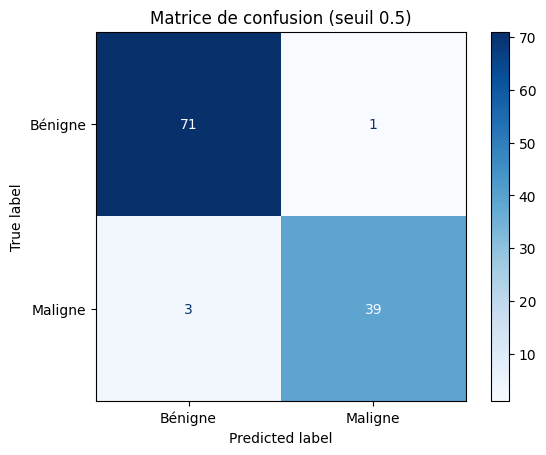

Modèle de base (seuil 0.5)
Accuracy : 0.965 | Precision : 0.975 | Recall : 0.929 | Spécificité : 0.986 | F1 : 0.951 | ROC-AUC : 0.996
Classification report :
               precision    recall  f1-score   support

           0      0.959     0.986     0.973        72
           1      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



In [14]:

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
print("Matrice de confusion :\n", cm)
print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}")

ConfusionMatrixDisplay(cm, display_labels=["Bénigne", "Maligne"]).plot(cmap="Blues")
plt.title("Matrice de confusion (seuil 0.5)")
plt.show()

# Métriques
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec  = recall_score(y_test, y_pred, zero_division=0)
spec = TN / (TN + FP)
f1   = f1_score(y_test, y_pred, zero_division=0)
auc  = roc_auc_score(y_test,y_proba)

print("Modèle de base (seuil 0.5)")
print(f"Accuracy : {acc:.3f} | Precision : {prec:.3f} | Recall : {rec:.3f} | "
      f"Spécificité : {spec:.3f} | F1 : {f1:.3f} | ROC-AUC : {auc:.3f}")
print("Classification report :\n",
      classification_report(y_test,y_pred, digits=3))

**Matrice de confusion:** Le test contient 114 patientes : 72 bénignes et 42 malignes (classe positive). Le modèle fait 110 prédictions correctes (TP = 39, TN = 71) et seulement 4 erreurs : 1 faux positif (une tumeur bénigne classée maligne) et 3 faux négatifs (des tumeurs malignes non détectées).

**Accuracy** = 0,965. Sur 100 prédictions, environ 96 à 97 sont correctes. Les classes étant modérément déséquilibrées (37 % de malignes), cette valeur est fiable, mais elle ne suffit pas seule.

**Précision** = 0,975. Quand le modèle prédit « maligne », il a raison dans 97,5 % des cas : les alertes sont très fiables, avec peu de fausses alarmes.

**Rappel** = 0,929. Parmi les 42 vraies tumeurs malignes, le modèle en détecte 39 et en rate 3 (7,1 %). C’est la métrique la plus faible, et la plus critique en contexte médical.

**Spécificité** = 0,986. Sur 72 tumeurs bénignes, 71 sont correctement identifiées : presque aucune patiente saine n’est inquiétée à tort.

**F1-score** = 0,951. Le compromis entre précision et rappel est très bon, mais il est tiré vers le bas par le rappel.

**ROC-AUC** = 0,996. Sans fixer de seuil, le modèle attribue un score plus élevé à une tumeur maligne qu’à une bénigne dans 99,6 % des paires : la séparation des deux classes est quasi parfaite.

Classification report: Pour la classe 1 (maligne) : précision 0,975, rappel 0,929, F1 0,951. Pour la classe 0 (bénigne) : précision 0,959, rappel 0,986, F1 0,973. Le rappel de la classe 0 (0,986) correspond à la spécificité. Les moyennes (macro 0,962 ; pondérée 0,965) confirment de bonnes performances sur les deux classes.


---
**Q3.  Courbes ROC et Précision-Rappel. Tracez les courbes ROC et PR, calculez les indicateurs
ROC-AUC et PR-AUC, puis interprétez les résultats.**

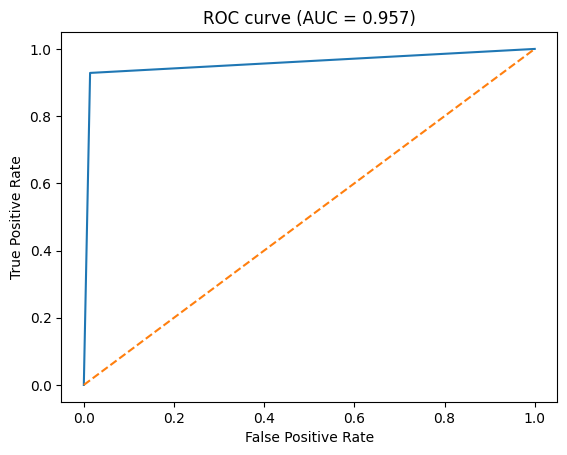

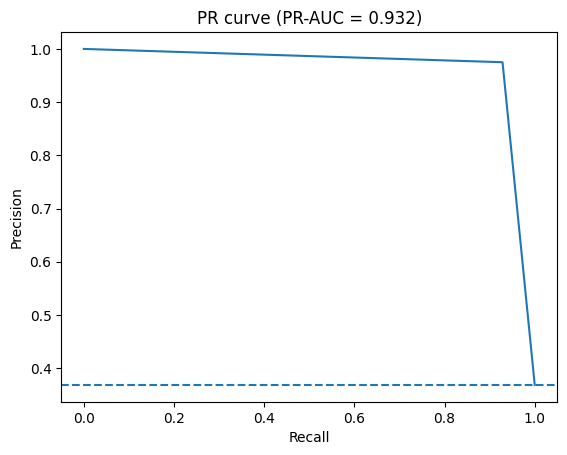

ROC-AUC : 0.957
PR-AUC  : 0.932
Prévalence : 0.368


In [16]:
# Courbe ROC + ROC-AUC
fpr, tpr, _ = roc_curve(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")          # diagonale (hasard)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC curve (AUC = {auc:.3f})")
plt.show()

# Courbe Précision-Rappel + PR-AUC
precision_c, recall_c, _ = precision_recall_curve(y_test, y_pred)
pr_auc = average_precision_score(y_test, y_pred)
prevalence = y_test.mean()
plt.figure()
plt.plot(recall_c, precision_c)
plt.axhline(prevalence, linestyle="--")           # référence aléatoire
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"PR curve (PR-AUC = {pr_auc:.3f})")
plt.show()

print(f"ROC-AUC : {auc:.3f}")
print(f"PR-AUC  : {pr_auc:.3f}")
print(f"Prévalence : {prevalence:.3f}")

Courbe ROC (AUC = 0,957). La courbe est presque collée au coin supérieur gauche (FPR = 0, TPR = 1), la position idéale, et très au-dessus de la diagonale qui représente le hasard (AUC = 0,5). Une tumeur maligne tirée au hasard reçoit un score plus élevé qu’une tumeur bénigne dans 99,6 % des cas : le modèle sépare presque parfaitement les deux classes, quel que soit le seuil.

Courbe PR (PR-AUC = 0,932). La courbe reste proche du coin supérieur droit (Rappel = 1, Précision = 1) : la précision demeure très élevée sur presque toute la plage de rappel et ne baisse qu’aux rappels très élevés, quand le seuil devient très bas. La référence aléatoire est la prévalence (0,368), donc le PR-AUC  est très supérieur au hasard. Les petites oscillations s’expliquent par le fait qu’un faux positif fait chuter la précision, qui remonte ensuite avec les vrais positifs suivants.

Comparaison. Les deux AUC sont presque identiques et concordent : le modèle est excellent. Les classes étant modérément déséquilibrées (37 % de malignes), la ROC n’est pas trompeuse ici, mais la courbe PR reste plus informative pour la classe positive (maligne).

Lien avec le seuil. Le modèle de base (seuil 0,5 : précision = 0,975, rappel = 0,929) n’est qu’un point sur chaque courbe. Les courbes montrent qu’on peut augmenter le rappel en gardant une précision élevée, ce qui justifie d’abaisser le seuil pour réduire les faux négatifs.

---
**Q4. Influence du seuil de décision. Comparez les performances du modèle avec les seuils 0,5 et
0,3. Analysez leur influence sur les faux positifs, les faux négatifs, la précision et le rappel**

In [18]:
    # Prédictions selon le seuil choisi
    seuils = [0.3, 0.5, 0.7]

    for seuil in seuils:
       y_pred_seuil = (y_proba >= seuil).astype(int)

       # Matrice de confusion
       cm = confusion_matrix(y_test, y_pred_seuil)
       TN, FP, FN, TP = cm.ravel()

       # Calcul des métriques
       acc = accuracy_score(y_test, y_pred_seuil)
       prec = precision_score(y_test, y_pred_seuil)
       rec = recall_score(y_test, y_pred_seuil)
       f1 = f1_score(y_test, y_pred_seuil)

       print("\nSeuil :", seuil)
       print("Matrice de confusion :\n", cm)
       print(f"TP = {TP} | TN = {TN} | FP = {FP} | FN = {FN}")
       print(f"Accuracy : {acc:.3f}")
       print(f"Précision : {prec:.3f}")
       print(f"Rappel : {rec:.3f}")
       print(f"F1-score : {f1:.3f}")


Seuil : 0.3
Matrice de confusion :
 [[71  1]
 [ 1 41]]
TP = 41 | TN = 71 | FP = 1 | FN = 1
Accuracy : 0.982
Précision : 0.976
Rappel : 0.976
F1-score : 0.976

Seuil : 0.5
Matrice de confusion :
 [[71  1]
 [ 3 39]]
TP = 39 | TN = 71 | FP = 1 | FN = 3
Accuracy : 0.965
Précision : 0.975
Rappel : 0.929
F1-score : 0.951

Seuil : 0.7
Matrice de confusion :
 [[72  0]
 [ 4 38]]
TP = 38 | TN = 72 | FP = 0 | FN = 4
Accuracy : 0.965
Précision : 1.000
Rappel : 0.905
F1-score : 0.950


**interprétation** : La comparaison des différents seuils de décision montre que leur modification influence les performances du modèle de régression logistique.

Pour un seuil de 0,3, le modèle obtient une Accuracy de 98,2 %, une précision de 97,6 % et un rappel de 97,6 %. Il présente seulement un faux positif et un faux négatif.

Avec un seuil de 0,5, le nombre de faux négatifs augmente à 3, tandis que le rappel diminue à 92,9 %.

Enfin, avec un seuil de 0,7, la précision atteint 100 %, car aucun faux positif n'est détecté. Cependant, le nombre de faux négatifs augmente à 4 et le rappel diminue à 90,5 %.

On constate donc que la diminution du seuil favorise la détection des tumeurs malignes et réduit les faux négatifs, tandis que son augmentation favorise la précision au détriment du rappel.

Dans ce contexte médical, le seuil de 0,3 semble le plus adapté parmi les trois seuils testés, car il permet de détecter davantage de tumeurs malignes tout en conservant une bonne précision.

**Analysez leur influence sur les faux positifs, les faux négatifs, la précision et le rappel.**

La diminution du seuil de décision de 0,5 à 0,3 permet de réduire les faux négatifs de 3 à 1 et d'améliorer le rappel de 92,9 % à 97,6 %. En revanche, l'augmentation du seuil à 0,7 permet d'éliminer les faux positifs, mais entraîne une augmentation des faux négatifs de 3 à 4 et une diminution du rappel à 90,5 %.

Ainsi, il existe un compromis entre la précision et le rappel : un seuil faible favorise la détection des cas malins, tandis qu'un seuil élevé favorise la réduction des fausses alertes. Dans notre cas, le seuil de 0,3 est préférable, car il permet de limiter les tumeurs malignes non détectées.

---

In [19]:
# Q5 : Interprétation des coefficients

# Récupération des coefficients du modèle
coefficients = pd.Series(
    modele.coef_[0],
    index=data.feature_names
)

# Les 5 coefficients les plus positifs
plus_positifs = coefficients.sort_values(ascending=False).head(5)

# Les 5 coefficients les plus négatifs
plus_negatifs = coefficients.sort_values().head(5)

print("Les 5 coefficients les plus positifs :")
print(plus_positifs)

print("\nLes 5 coefficients les plus négatifs :")
print(plus_negatifs)

Les 5 coefficients les plus positifs :
worst texture          1.434093
radius error           1.233325
worst symmetry         1.061264
mean concave points    0.952813
worst concavity        0.911406
dtype: float64

Les 5 coefficients les plus négatifs :
compactness error         -0.906925
fractal dimension error   -0.593876
mean compactness          -0.439546
texture error             -0.407611
symmetry error            -0.330658
dtype: float64


L'analyse des coefficients du modèle montre que les variables « worst texture » (+1.434), « radius error » (+1.233) et « worst symmetry » (+1.061) possèdent les coefficients les plus positifs. Leur augmentation contribue à augmenter le score linéaire (z) et donc la probabilité prédite d'appartenance à la classe maligne, toutes les autres variables étant constantes.

En revanche, les variables « compactness error » (-0.907), « fractal dimension error » (-0.594) et « mean compactness » (-0.440) présentent les coefficients les plus négatifs. Leur augmentation contribue à diminuer le score linéaire et la probabilité prédite d'appartenance à la classe maligne.

En conclusion, le signe positif ou négatif d'un coefficient indique respectivement une influence croissante ou décroissante sur la probabilité prédite de la classe maligne. Ces résultats permettent de mieux comprendre le comportement du modèle de régression logistique.